# Riesgo de impago y asignación de límites de crédito

**Pregunta de negocio:** ¿qué tarjetahabientes tienen alta probabilidad de no pagar el próximo mes, y a cuáles podemos ofrecer un aumento de límite con bajo riesgo?

**Datos:** [Default of Credit Card Clients (UCI)](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients), 30.000 clientes de un banco de Taiwán (2005). Licencia CC BY 4.0.

**Contenido**
1. Carga de datos
2. Exploración
3. Ingeniería de variables
4. Modelos y métricas de riesgo (AUC, Gini, KS)
5. Bandas de riesgo
6. Política de aumento de límite

In [1]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PALETA = ["#6B2D8C", "#7A1F3D", "#B23A6A", "#D9C2E8", "#3E2447"]
sns.set_theme(style="whitegrid", palette=PALETA)
RANDOM_STATE = 42

DATA_DIR = Path("data/raw")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

## 1. Carga de datos
Si la descarga automática falla, baja el zip desde la página del dataset y coloca `default of credit card clients.xls` en `data/raw/`.

In [3]:
URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
XLS = DATA_DIR / "default of credit card clients.xls"


def descargar_datos():
    if XLS.exists():
        return
    print("Descargando Default of Credit Card Clients desde UCI...")
    with urllib.request.urlopen(URL) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
    miembro = next(n for n in z.namelist() if n.endswith(".xls"))
    XLS.write_bytes(z.read(miembro))


descargar_datos()
df = pd.read_excel(XLS, header=1)
df = df.rename(columns={"default payment next month": "impago"}).drop(columns=["ID"])
print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,impago
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Exploración
Variables clave:
- `LIMIT_BAL`: límite de crédito
- `PAY_0`, `PAY_2`…`PAY_6`: estado de pago de los últimos 6 meses (-1 = pagó a tiempo, 1 = un mes de atraso, 2 = dos meses…)
- `BILL_AMT*`: saldo facturado; `PAY_AMT*`: monto pagado

Tasa de impago: 22.1%


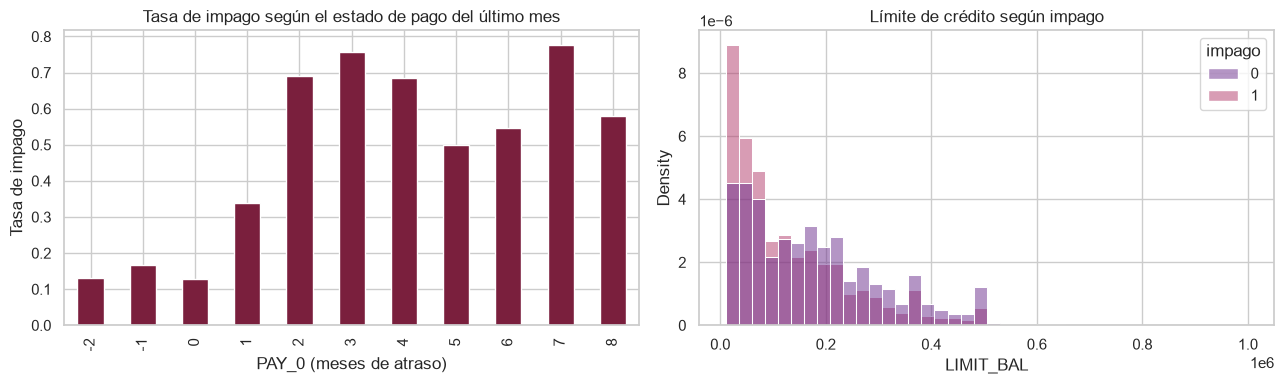

In [4]:
print(f"Tasa de impago: {df['impago'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby("PAY_0")["impago"].mean().plot.bar(ax=axes[0], color=PALETA[1])
axes[0].set_title("Tasa de impago según el estado de pago del último mes")
axes[0].set_xlabel("PAY_0 (meses de atraso)")
axes[0].set_ylabel("Tasa de impago")

sns.histplot(data=df, x="LIMIT_BAL", hue="impago", bins=40, stat="density",
             common_norm=False, ax=axes[1], palette=[PALETA[0], PALETA[2]])
axes[1].set_title("Límite de crédito según impago")
plt.tight_layout()
plt.show()

**Lectura:** el comportamiento de pago reciente es la señal más fuerte: con dos o más meses de atraso, la tasa de impago se dispara.

## 3. Ingeniería de variables
Creamos indicadores que un analista de riesgo usaría:
- **utilización**: saldo facturado / límite
- **meses con atraso** y **atraso máximo** en el semestre
- **ratio de pago**: lo pagado / lo facturado

In [5]:
PAY = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]

datos = df.copy()
datos["EDUCATION"] = datos["EDUCATION"].replace({0: 4, 5: 4, 6: 4})  # 4 = otros
datos["MARRIAGE"] = datos["MARRIAGE"].replace({0: 3})                # 3 = otros
datos["utilizacion"] = (datos["BILL_AMT1"] / datos["LIMIT_BAL"]).clip(-1, 3)
datos["meses_con_atraso"] = (datos[PAY] > 0).sum(axis=1)
datos["atraso_maximo"] = datos[PAY].max(axis=1)
facturado = datos[BILL].clip(lower=0).sum(axis=1).replace(0, np.nan)
datos["ratio_pago"] = (datos[PAMT].sum(axis=1) / facturado).fillna(1).clip(0, 5)

for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    datos[col] = datos[col].astype(str)

y = datos.pop("impago")
X = datos
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

## 4. Modelos y métricas de riesgo
En banca, además del AUC se reportan el **Gini** (2·AUC − 1) y el **estadístico KS**, la máxima separación entre las distribuciones de buenos y malos pagadores.

In [6]:
def metricas_riesgo(y_real, p):
    auc = roc_auc_score(y_real, p)
    fpr, tpr, _ = roc_curve(y_real, p)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": np.max(tpr - fpr)}


modelos = {
    "Regresión logística": LogisticRegression(max_iter=2000),
    "Gradient boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE
    ),
}

entrenados, resultados = {}, []
for nombre, modelo in modelos.items():
    pipe = Pipeline([("pre", clone(preprocesador)), ("modelo", modelo)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    entrenados[nombre] = pipe
    resultados.append({"Modelo": nombre, **metricas_riesgo(y_test, p)})

resultados = pd.DataFrame(resultados).set_index("Modelo").round(3)
resultados

,AUC,Gini,KS
Modelo,,,
Regresión logística,0.75,0.50,0.396
Gradient boosting,0.78,0.56,0.421


Modelo elegido: Gradient boosting


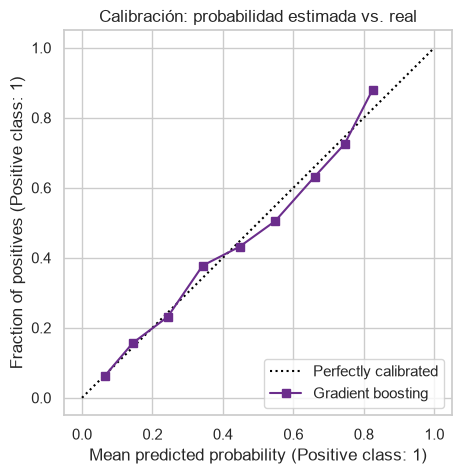

In [7]:
mejor_nombre = resultados["AUC"].idxmax()
mejor = entrenados[mejor_nombre]
prob = mejor.predict_proba(X_test)[:, 1]
print("Modelo elegido:", mejor_nombre)

fig, ax = plt.subplots(figsize=(5, 5))
CalibrationDisplay.from_predictions(y_test, prob, n_bins=10, ax=ax, name=mejor_nombre, color=PALETA[0])
ax.set_title("Calibración: probabilidad estimada vs. real")
plt.show()

## 5. Bandas de riesgo
Dividimos a los clientes en cinco bandas de igual tamaño, de **A** (menor riesgo) a **E** (mayor riesgo). Una buena segmentación muestra tasas de impago crecientes de A a E.

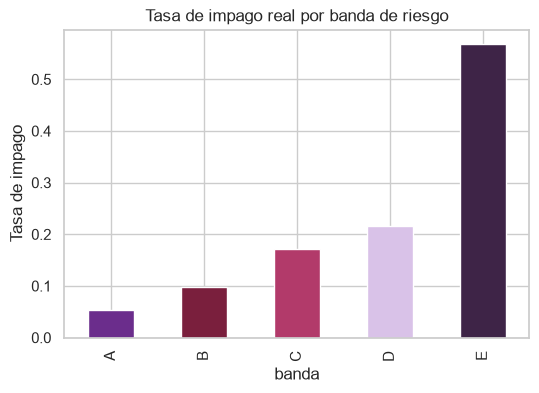

,clientes,prob_media,tasa_impago_real,limite_promedio
banda,,,,
A,1800,5.4%,5.3%,"269,178"
B,1800,9.9%,9.8%,"178,300"
C,1800,14.7%,17.1%,"150,828"
D,1800,23.2%,21.6%,"135,338"
E,1800,56.7%,56.8%,"103,606"


In [8]:
resultado = X_test.copy()
resultado["prob_impago"] = prob
resultado["impago_real"] = y_test.values
resultado["banda"] = pd.qcut(resultado["prob_impago"].rank(method="first"), 5, labels=list("ABCDE"))

bandas = resultado.groupby("banda", observed=True).agg(
    clientes=("impago_real", "size"),
    prob_media=("prob_impago", "mean"),
    tasa_impago_real=("impago_real", "mean"),
    limite_promedio=("LIMIT_BAL", "mean"),
)

ax = bandas["tasa_impago_real"].plot.bar(color=PALETA, figsize=(6, 4))
ax.set_title("Tasa de impago real por banda de riesgo")
ax.set_ylabel("Tasa de impago")
plt.show()
bandas.style.format({"prob_media": "{:.1%}", "tasa_impago_real": "{:.1%}", "limite_promedio": "{:,.0f}"})

## 6. Política de aumento de límite
Regla propuesta (ajustable): ofrecer aumento a clientes que
- están en las bandas **A o B**,
- usan al menos el **60 %** de su límite (lo necesitan), y
- **no tuvieron atrasos** en los últimos 6 meses.

In [9]:
candidatos = resultado[
    resultado["banda"].isin(["A", "B"])
    & (resultado["utilizacion"] >= 0.6)
    & (resultado["meses_con_atraso"] == 0)
]

resumen = pd.DataFrame({
    "Grupo": ["Toda la cartera", "Candidatos a aumento"],
    "Clientes": [len(resultado), len(candidatos)],
    "Tasa de impago": [resultado["impago_real"].mean(), candidatos["impago_real"].mean()],
})
print(resumen.to_string(index=False, formatters={"Tasa de impago": "{:.1%}".format}))

candidatos.sort_values("prob_impago").to_csv(OUT_DIR / "candidatos_aumento_limite.csv", index=False)
resultado.to_csv(OUT_DIR / "clientes_con_banda.csv", index=False)

               Grupo  Clientes Tasa de impago
     Toda la cartera      9000          22.1%
Candidatos a aumento       914          10.8%


## Conclusiones
- El historial de pagos reciente domina la predicción; las variables construidas (atraso máximo, utilización, ratio de pago) ordenan bien el riesgo.
- Las bandas A–E separan claramente a buenos y malos pagadores, lo que permite políticas diferenciadas.
- El grupo de candidatos a aumento de límite tiene una tasa de impago muy inferior a la de la cartera: se puede crecer en crédito sin aumentar el riesgo.
- Siguientes pasos: validar estabilidad en el tiempo (PSI) y definir el monto del aumento según capacidad de pago.